In [1]:
import re

import matplotlib.pyplot as plt
import pandas as pd
from openfast_toolbox.io import FASTOutputFile

In [2]:
of_outb_file = '../Verification/linear_wave_results/standalone_openfast.outb'
ahm_of_outb_file = '../Verification/linear_wave_results/ahm_openfast.outb'
ahm_md_out_file = '../Verification/linear_wave_results/ahm_moordyn.out'

In [3]:
iteration = slice(-60000, -1)

In [4]:
of_outb_df = FASTOutputFile(of_outb_file).toDataFrame()
of_outb_df = of_outb_df.rename(columns=lambda x: re.sub('_.*$', '', x))[-60000:]
ahm_of_out_df = FASTOutputFile(ahm_of_outb_file).toDataFrame()
ahm_md_out_df = pd.read_csv(ahm_md_out_file, sep='\s+', skiprows=[1], na_values=['***************'])
ahm_out_df = pd.concat([ahm_of_out_df, ahm_md_out_df], axis=1)
ahm_out_df = ahm_out_df.rename(columns=lambda x: re.sub('_.*$', '', x))[-60001:-1]
ahm_out_df = ahm_out_df.loc[:, ~ahm_out_df.columns.duplicated()]

In [5]:
t = of_outb_df['Time']

In [6]:
ahm_out_df

,Time,PtfmHeave,PtfmPitch,PtfmRoll,PtfmSurge,PtfmSway,PtfmYaw,FAIRTEN1,FAIRTEN2,FAIRTEN3,...,LINE1N1VZ,LINE2N1VX,LINE2N1VY,LINE2N1VZ,LINE3N1VX,LINE3N1VY,LINE3N1VZ,AnchTen1,AnchTen2,AnchTen3
6002,60.02,-5.965617,0.284229,-0.000103,8.710314,0.012927,-0.000365,9.702769e+06,9.801802e+06,9.802253e+06,...,-1.721552,1.234655,-0.095313,1.752285,1.181020,0.033372,1.776848,12792200.0,12089500.0,12095200.0
6003,60.03,-5.959171,0.281306,-0.000123,8.699541,0.012909,-0.000405,9.702814e+06,9.801617e+06,9.802075e+06,...,-1.726327,1.239938,-0.095378,1.758906,1.186046,0.032793,1.783919,12791800.0,12090300.0,12096000.0
6004,60.04,-5.952560,0.278383,-0.000144,8.688960,0.012892,-0.000446,9.702865e+06,9.801433e+06,9.801890e+06,...,-1.730924,1.245222,-0.095443,1.765434,1.191022,0.032206,1.790990,12791400.0,12091000.0,12096700.0
6005,60.05,-5.945948,0.275459,-0.000165,8.677995,0.012875,-0.000487,9.702919e+06,9.801256e+06,9.801712e+06,...,-1.735522,1.250452,-0.095498,1.771868,1.195947,0.031616,1.797869,12790900.0,12091800.0,12097500.0
6006,60.06,-5.939337,0.272518,-0.000186,8.667221,0.012858,-0.000528,9.702973e+06,9.801071e+06,9.801534e+06,...,-1.740032,1.255629,-0.095553,1.778303,1.200872,0.031021,1.804749,12790500.0,12092500.0,12098300.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65997,659.97,-5.902314,0.151238,0.000963,5.978517,0.001252,0.002805,9.718716e+06,9.644279e+06,9.643825e+06,...,1.751212,-1.494537,0.079099,-1.969489,-1.430740,-0.008219,-2.000014,12670700.0,12190900.0,12185300.0
65998,659.98,-5.910082,0.154235,0.000984,5.987943,0.001253,0.002850,9.718562e+06,9.644556e+06,9.644095e+06,...,1.748825,-1.494431,0.078594,-1.969768,-1.430690,-0.007761,-2.000205,12670900.0,12190000.0,12184400.0
65999,659.99,-5.917851,0.157249,0.001006,5.997370,0.001255,0.002894,9.718407e+06,9.644825e+06,9.644372e+06,...,1.746260,-1.494273,0.078090,-1.969862,-1.430639,-0.007303,-2.000396,12671100.0,12189100.0,12183500.0
66000,660.00,-5.925619,0.160246,0.001027,6.006796,0.001256,0.002939,9.718249e+06,9.645102e+06,9.644643e+06,...,1.743696,-1.494009,0.077585,-1.969862,-1.430436,-0.006844,-2.000396,12671400.0,12188100.0,12182500.0


In [7]:
var_names = ['PtfmSurge', 'PtfmHeave', 'PtfmPitch', 'FairTen1', 'FairTen2', 'FairTen3', 'AnchTen1', 'AnchTen2', 'AnchTen3']

In [8]:
fig = plt.figure(figsize=(12, 12), tight_layout=True)
nrows = 3
ncols = 3
mooring_ylims = [0.75e7, 1.5e7]

<Figure size 1200x1200 with 0 Axes>

In [9]:
def plot_vars(of_data, ahm_data, t, fig, ax_idx, title, ylims):
    ax = fig.add_subplot(nrows, ncols, ax_idx+1)
    if ylims is not None:
        ax.set_ylim(ylims)
    ax.plot(t, of_data, color='black', label='OpenFAST')
    ax.plot(t, ahm_data, color='blue', label='AHM model')
    ax.set_title(title)
    return ax.get_legend_handles_labels()

In [10]:
for i, var_name in enumerate(var_names):
    if 'AnchTen' in var_name:
        of_var_name = var_name.upper()
        ahm_var_name = var_names[i-3].upper()
        ylims = mooring_ylims
    elif 'FairTen' in var_name:
        of_var_name = var_name.upper()
        ahm_var_name = var_names[i+3]
        ylims = mooring_ylims
    else:
        of_var_name = var_name
        ahm_var_name = var_name
        ylims = None
    handles, labels = plot_vars(of_outb_df[of_var_name],
                                ahm_out_df[ahm_var_name],
                                t, fig, i, var_name, ylims)
fig.legend(handles, labels, bbox_to_anchor=[0.63, -0.005, 0, 0], ncols=2, frameon=False)
fig.show()

C:\Users\mcdevin\AppData\Local\Temp\ipykernel_13008\1320941682.py:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


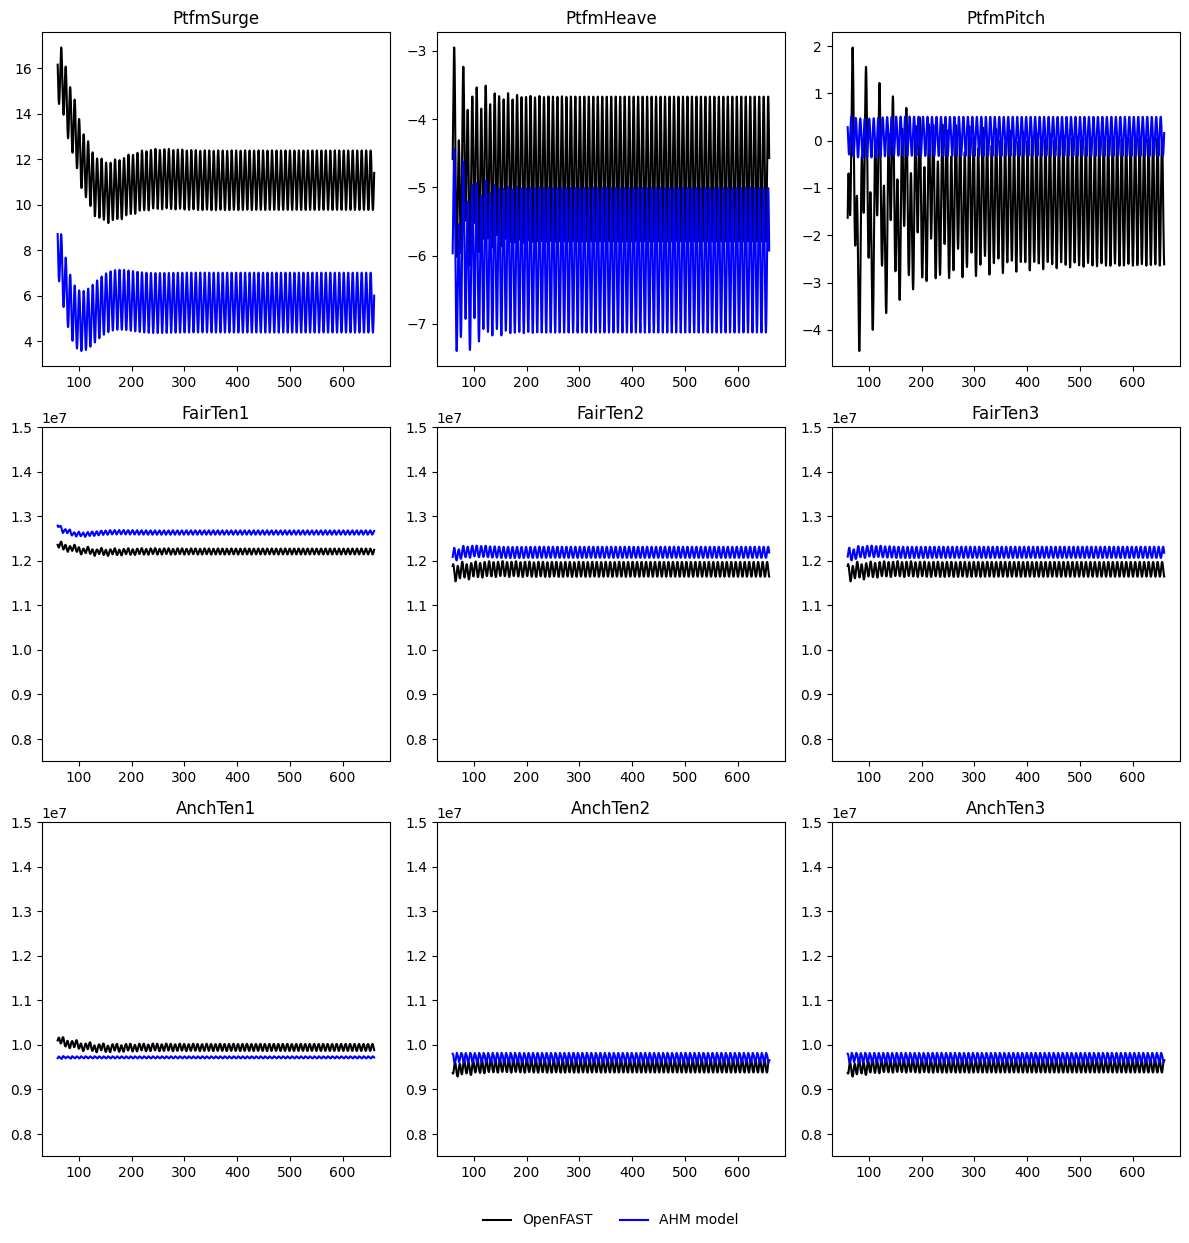

In [11]:
fig